# Midterm 1 — Student Performance Prediction

Name: Sumi Li <br> Github Username: SumiLi-1 <br> USC ID: 5751493481

## 1. Import libraries and load data

In [10]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style='whitegrid')

df = pd.read_csv(data_file, sep=';')
print('Dataset shape:', df.shape)
df.head()

Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [11]:
# Basic exploration
df.info()

print('\nSummary statistics:')
display(df.describe(include='all').T)

print('Missing values in each column:')
display(df.isna().sum().to_frame('missing_values'))

<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 non-null    str  
 12  traveltime  395 non-null    int64
 13  studytime   395 non-null    int64
 14  failures    395 non-null    int64
 15  schoolsup   395 non-null    str  
 16  famsup      395 non-null    str  
 17  paid        395 non-null    str  
 18  activities  395 non-null    str  
 19  nursery     395 non-null    str  
 20  higher      395 non-null    str  
 21  inte

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,395,2,GP,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,395,2,F,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,395.0,NaN,NaN,NaN,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
address,395,2,U,307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,395,2,GT3,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,395,2,T,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,395.0,NaN,NaN,NaN,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,NaN,NaN,NaN,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
Mjob,395,5,other,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,395,5,other,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values in each column:


,missing_values
school,0
sex,0
age,0
address,0
famsize,0
Pstatus,0
Medu,0
Fedu,0
Mjob,0
Fjob,0


## 2. Pre-processing

In [12]:
# Selected predictors: `age`, `studytime`, `schoolsup`, `goout`, `Dalc`, `Walc`, `health`, and `absences`. `schoolsup` is encoded as 0/1
#`alc` is the average of `Dalc` and `Walc`.
selected = df[['age', 'studytime', 'schoolsup', 'goout', 'Dalc', 'Walc',
               'health', 'absences', 'G3']].copy()

selected['schoolsup'] = selected['schoolsup'].map({'no': 0, 'yes': 1})
selected['alc'] = selected[['Dalc', 'Walc']].mean(axis=1)
selected = selected.drop(columns=['Dalc', 'Walc'])

print('First five rows after pre-processing:')
display(selected.head())

feature_names = ['age', 'studytime', 'schoolsup', 'goout', 'health', 'absences', 'alc']
X = selected[feature_names]
y = selected['G3']

First five rows after pre-processing:


,age,studytime,schoolsup,goout,health,absences,G3,alc
0,18,2,1,4,3,6,6,1.0
1,17,2,0,3,3,4,6,1.0
2,15,2,1,2,3,10,10,2.5
3,15,3,0,2,5,2,15,1.0
4,16,2,0,2,5,4,10,1.5


## 3. Outlier detection using IQR

,IQR_outlier_count
age,1
studytime,27
schoolsup,51
goout,0
health,0
absences,15
alc,9


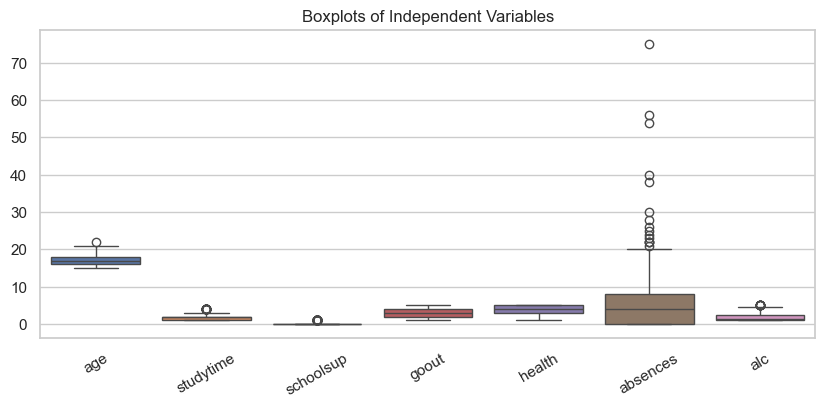

In [13]:
outlier_counts = {}
for column in feature_names:
    q1 = X[column].quantile(0.25)
    q3 = X[column].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_counts[column] = ((X[column] < lower) | (X[column] > upper)).sum()

outlier_table = pd.DataFrame.from_dict(outlier_counts, orient='index', columns=['IQR_outlier_count'])
display(outlier_table)

plt.figure(figsize=(10, 4))
sns.boxplot(data=X)
plt.title('Boxplots of Independent Variables')
plt.xticks(rotation=30)
plt.show()

## 4. Standardization and PCA

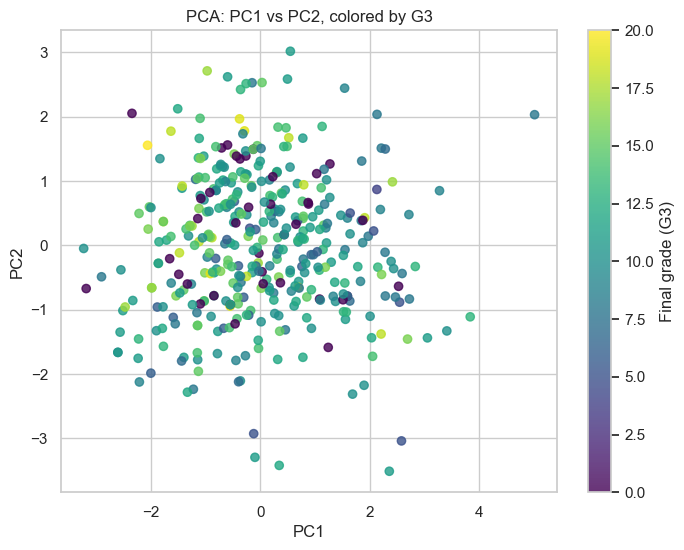

,PC1_loading,PC2_loading
age,0.381940,0.589260
studytime,-0.329734,0.385671
schoolsup,-0.248184,-0.464202
goout,0.493755,-0.139613
health,0.080545,-0.400925
absences,0.280106,0.182798
alc,0.595871,-0.273677


Explained variance ratio:
PC1    0.236757
PC2    0.171366
PC3    0.151961
PC4    0.140408
PC5    0.126730
PC6    0.094774
PC7    0.078004
dtype: float64

Largest absolute contributors:
PC1: alc
PC2: age


In [14]:
scaler = StandardScaler()
X_standardized = pd.DataFrame(scaler.fit_transform(X), columns=feature_names, index=X.index)

pca = PCA()
pca_scores = pca.fit_transform(X_standardized)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(pca_scores[:, 0], pca_scores[:, 1], c=y, cmap='viridis', alpha=0.8)
plt.colorbar(scatter, label='Final grade (G3)')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA: PC1 vs PC2, colored by G3')
plt.show()

loadings = pd.DataFrame(pca.components_[:2].T, index=feature_names, columns=['PC1_loading', 'PC2_loading'])
display(loadings)

print('Explained variance ratio:')
print(pd.Series(pca.explained_variance_ratio_, index=[f'PC{i+1}' for i in range(len(feature_names))]))
print('\nLargest absolute contributors:')
print('PC1:', loadings['PC1_loading'].abs().idxmax())
print('PC2:', loadings['PC2_loading'].abs().idxmax())

## 5. Train/test split and three linear models
The split uses 80% training data and 20% testing data, with random seed 552. Ridge and Lasso use α = 0.1.

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X_standardized, y, test_size=0.20, random_state=552
)

models = {
    'Linear Regression': LinearRegression(),
    'Ridge (alpha=0.1)': Ridge(alpha=0.1),
    'Lasso (alpha=0.1)': Lasso(alpha=0.1, max_iter=10000)
}

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)

## 6. Test-set evaluation and coefficients

In [16]:
results = []
for name, predicted in predictions.items():
    results.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, predicted),
        'RMSE': mean_squared_error(y_test, predicted) ** 0.5,
        'R2': r2_score(y_test, predicted)
    })

results_df = pd.DataFrame(results).set_index('Model').round(4)
display(results_df)

print('Best model by MAE:', results_df['MAE'].idxmin())
print('Best model by RMSE:', results_df['RMSE'].idxmin())
print('Best model by R2:', results_df['R2'].idxmax())

coefficient_table = pd.DataFrame({name: model.coef_ for name, model in models.items()}, index=feature_names)
coefficient_table.loc['intercept'] = [model.intercept_ for model in models.values()]
display(coefficient_table.round(4))

,MAE,RMSE,R2
Model,,,
Linear Regression,3.4180,4.7558,0.0282
Ridge (alpha=0.1),3.4181,4.7559,0.0282
Lasso (alpha=0.1),3.4471,4.7938,0.0126


Best model by MAE: Linear Regression
Best model by RMSE: Linear Regression
Best model by R2: Linear Regression


,Linear Regression,Ridge (alpha=0.1),Lasso (alpha=0.1)
age,-0.7811,-0.7807,-0.6304
studytime,0.4448,0.4447,0.3491
schoolsup,-0.6825,-0.6822,-0.5475
goout,-0.5825,-0.5823,-0.4856
health,-0.2433,-0.2432,-0.1416
absences,0.1928,0.1927,0.0720
alc,0.0371,0.0369,-0.0000
intercept,10.6294,10.6294,10.6251


Since all predictors were standardized, each coefficient represents the expected change in final grade (G3) associated with a one-standard-deviation increase in that predictor, while holding the other variables constant.

- age has a negative relationship with G3 (Linear Regression coefficient = −0.781). Older students tend to have lower predicted final grades.
- studytime has a positive relationship (0.445). More study time is associated with higher predicted final grades.
- schoolsup has a negative coefficient (−0.683). After controlling for the other selected variables, receiving school support is associated with a lower predicted G3. This should not be interpreted as school support causing lower grades; it may indicate that students receiving support were already experiencing academic difficulty.
- goout has a negative relationship (−0.583). Students who go out more frequently tend to have lower predicted final grades.
- health has a weak negative relationship (−0.243), so better self-reported health is only slightly associated with lower predicted G3 in this model.
- absences has a very weak positive coefficient (0.193). This unexpected result is small and should be interpreted cautiously because the overall model fit is low.
- alc has almost no relationship with G3 in Linear Regression (0.037). In the Lasso model, its coefficient becomes exactly zero, indicating that alcohol consumption does not add useful predictive information after the other variables are considered.

## 7. Residual analysis
A random cloud centered around zero suggests that the linear-model errors do not show a strong systematic pattern.

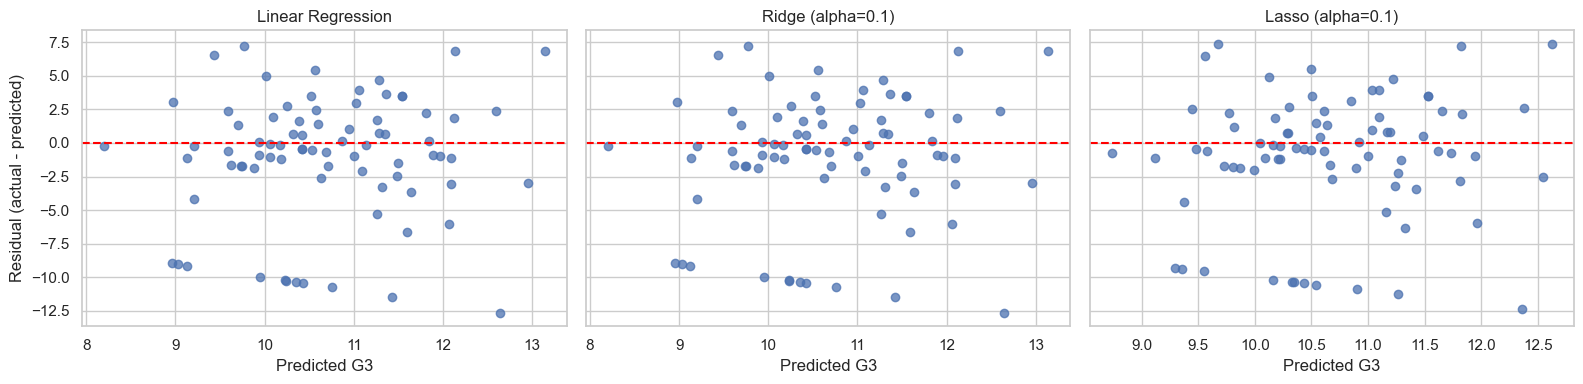

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, (name, predicted) in zip(axes, predictions.items()):
    residuals = y_test - predicted
    ax.scatter(predicted, residuals, alpha=0.75)
    ax.axhline(0, color='red', linestyle='--')
    ax.set_title(name)
    ax.set_xlabel('Predicted G3')
axes[0].set_ylabel('Residual (actual - predicted)')
plt.tight_layout()
plt.show()

## 8. Brief discussion

- **R² interpretation:** R² is the proportion of variation in final grade explained by the predictors on the test set. A larger R² indicates better explanatory and predictive performance; a negative R² means the model is worse than predicting the test-set mean. The low $R^2$ values indicate that these behavioral and background variables are insufficient to accurately predict the final grade. Furthermore, the fact that regularization yielded no significant improvement suggests that the model is primarily limited by a lack of informative features, rather than merely overfitting.
- **Feature relationships:** Because predictors are standardized, a positive coefficient means higher values of that feature are associated with a higher predicted `G3`, holding other features fixed. A negative coefficient means the opposite. The coefficient table gives the observed direction and relative effect size.
- **Ridge versus Lasso:** Ridge shrinks all coefficients toward zero but usually keeps every feature. Lasso can shrink some coefficients exactly to zero, which performs simple feature selection. In this analysis, Ridge produced nearly identical coefficients and evaluation results to ordinary Linear Regression (R² ≈ 0.028 for both). This suggests that, with α = 0.1, regularization did not substantially improve prediction performance. Therefore, there is no strong evidence that multicollinearity or overfitting is the main limitation of this model. Lasso had a slightly lower R² (about 0.013) and set the coefficient of alc to zero. This suggests that alc is redundant or provides little additional information for predicting G3 after accounting for the other features. Lasso also reduced the magnitudes of the remaining coefficients.
- **Effect of increasing α:** Stronger regularization makes coefficients smaller. This can reduce overfitting, but if α becomes too large it underfits the data, usually increasing MAE/RMSE and decreasing R². Increasing α creates a bias-variance tradeoff. A small increase in α may reduce overfitting and lower test-set MAE and RMSE, while increasing test-set R², if the original model has high variance. However, if α becomes too large, the model will underfit because the coefficients are forced too close to zero. In that case, MAE and RMSE will increase, while R² will decrease.For this dataset, Ridge with α = 0.1 performs almost exactly like ordinary Linear Regression, while Lasso with α = 0.1 performs slightly worse. Therefore, increasing α much further is unlikely to improve the test performance substantially. It would likely make MAE and RMSE larger and make R² smaller because the selected variables already contain limited information for predicting G3.
- **Possible feature engineering:** Add interaction terms (for example `studytime × absences`), nonlinear terms (such as `absences²`), categorical predictors from the original dataset, or prior grades `G1` and `G2` if predicting final grade is the goal. Cross-validation can select α and compare those additions fairly.